# Ferro Vision - Notebook 2: Visual Defect Detection (Casting Images)

**Goal:** classify top-view images of a submersible-pump impeller as **Defective (1)** or **Normal (0)**.

| Model | Type |
|---|---|
| **Custom CNN** | built from scratch (conv, pooling, dropout, dense) |
| **VGG16** | pretrained ImageNet backbone, fine-tuned |
| **MobileNetV2** | pretrained ImageNet backbone, fine-tuned |

**Framework:** TensorFlow / Keras 

**Outline**
1. Setup and configuration
2. Data cleaning and integrity checks
3. EDA
4. Stratified train / validation split
5. Data pipelines and augmentation
6. Custom CNN
7. Transfer learning (VGG16, MobileNetV2)
8. Validation comparison
9. Final test evaluation (once)
10. Best model and error analysis
11. Discussion
12. Saving models and artifacts

## 1. Setup and configuration

In [1]:
import os, json, random, shutil, hashlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, confusion_matrix,
                             ConfusionMatrixDisplay, roc_auc_score)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, callbacks

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

# ---------------- configuration ----------------
SEED        = 42
DATA_ROOT   = "../data/casting_data"     # <- folder that contains train/ and test/
SPLIT_DIR   = "../data/casting_split"    # created by this notebook (train/ val/ test/)
CLASS_NAMES = ["normal", "defective"] # index 0 = normal, index 1 = defective
BATCH       = 32
IMG_CNN     = 128                     # custom CNN input size
IMG_TL      = 224                     # VGG16 / MobileNetV2 input size
WEIGHTS     = "imagenet"              # use None only to smoke-test without downloading weights

EPOCHS_CNN  = 30                      # upper bounds; EarlyStopping stops sooner
EPOCHS_HEAD = 8                       # transfer learning stage 1: train new head only
EPOCHS_FT   = 12                      # transfer learning stage 2: fine-tune top layers
LR_CNN, LR_HEAD, LR_FT = 1e-3, 1e-3, 1e-5

random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)
os.makedirs("../models", exist_ok=True); os.makedirs("../artifacts", exist_ok=True)

print("TensorFlow:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU") or "none (CPU training will be slow)")

TensorFlow: 2.22.0-rc0
GPUs: none (CPU training will be slow)


## 2. Data cleaning and integrity checks

In [2]:
IMG_EXT = (".jpg", ".jpeg", ".png", ".bmp")

def find_split_dir(root, name):
    # Locate <root>/.../<name>/ that contains class sub-folders (handles nested Kaggle layouts)
    for dp, dn, _ in os.walk(root):
        if name in dn:
            cand = os.path.join(dp, name)
            if any(os.path.isdir(os.path.join(cand, s)) for s in os.listdir(cand)):
                return cand
    raise FileNotFoundError(f"Could not find a '{name}/' folder with class sub-folders under {root}")

def label_of(folder):
    # def_front -> defective ; ok_front / normal -> normal
    return "defective" if "def" in folder.lower() else "normal"

records = []
for split in ("train", "test"):
    sdir = find_split_dir(DATA_ROOT, split)
    print(f"{split}: {sdir} -> class folders {sorted(os.listdir(sdir))}")
    for cls_folder in sorted(os.listdir(sdir)):
        cdir = os.path.join(sdir, cls_folder)
        if not os.path.isdir(cdir):
            continue
        for fn in sorted(os.listdir(cdir)):
            if fn.lower().endswith(IMG_EXT):
                records.append({"path": os.path.join(cdir, fn), "orig_split": split,
                                "folder": cls_folder, "label": label_of(cls_folder)})

meta = pd.DataFrame(records)
assert set(meta["label"]) == set(CLASS_NAMES), f"Expected 2 classes, got {set(meta['label'])}"
print("\nImages indexed:", len(meta))
print(meta.groupby(["orig_split", "folder", "label"]).size())

train: ../data/casting_data\train -> class folders ['defective', 'normal']
test: ../data/casting_data\test -> class folders ['defective', 'normal']

Images indexed: 7348
orig_split  folder     label    
test        defective  defective     453
            normal     normal        262
train       defective  defective    3758
            normal     normal       2875
dtype: int64


In [3]:
# Corrupt-file check + image properties
ok, widths, heights, modes = [], [], [], []
for p in meta["path"]:
    try:
        with Image.open(p) as im:
            im.verify()
        with Image.open(p) as im:
            widths.append(im.size[0]); heights.append(im.size[1]); modes.append(im.mode)
        ok.append(True)
    except Exception as e:
        ok.append(False); widths.append(None); heights.append(None); modes.append(None)

meta["ok"], meta["w"], meta["h"], meta["mode"] = ok, widths, heights, modes
print("Corrupt / unreadable files:", (~meta["ok"]).sum())
print("\nImage sizes:\n", meta[meta.ok].groupby(["w", "h"]).size())
print("\nColour modes:\n", meta[meta.ok]["mode"].value_counts())

meta = meta[meta.ok].drop(columns="ok").reset_index(drop=True)

Corrupt / unreadable files: 0

Image sizes:
 w    h  
300  300    7348
dtype: int64

Colour modes:
 mode
RGB    7348
Name: count, dtype: int64


In [4]:
# Duplicate / leakage check: identical files within train, and train files that also appear in test
def md5(p):
    with open(p, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

meta["md5"] = meta["path"].map(md5)
tr, te = meta[meta.orig_split == "train"], meta[meta.orig_split == "test"]

print("Duplicate files inside train:", tr["md5"].duplicated().sum())
print("Test files that also exist in train:", te["md5"].isin(set(tr["md5"])).sum())

# Same file stored under both labels would indicate label noise
conflict = meta.groupby("md5")["label"].nunique()
print("Identical images carrying conflicting labels:", (conflict > 1).sum())
# Duplicates are only reported here (dropping them would change the counts the brief expects).
# If you see test/train overlap, mention it when you interpret very high scores.

Duplicate files inside train: 0
Test files that also exist in train: 64
Identical images carrying conflicting labels: 0


## 3. Exploratory data analysis

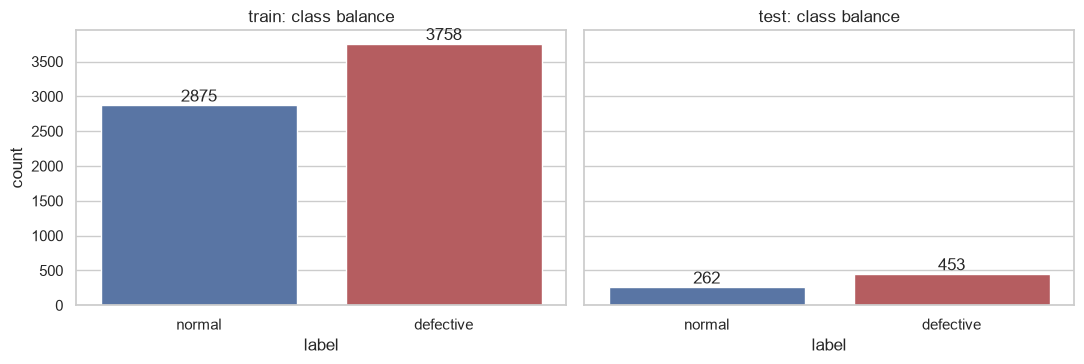

Train defective share: 56.7%  (mild imbalance -> class weights will be used)


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for a, split in zip(ax, ("train", "test")):
    sub = meta[meta.orig_split == split]
    sns.countplot(data=sub, x="label", order=CLASS_NAMES, ax=a, palette=["#4c72b0", "#c44e52"])
    a.set_title(f"{split}: class balance")
    for c in a.containers:
        a.bar_label(c)
plt.tight_layout(); plt.show()

counts = meta[meta.orig_split == "train"]["label"].value_counts()
print(f"Train defective share: {counts['defective'] / counts.sum():.1%}  (mild imbalance -> class weights will be used)")

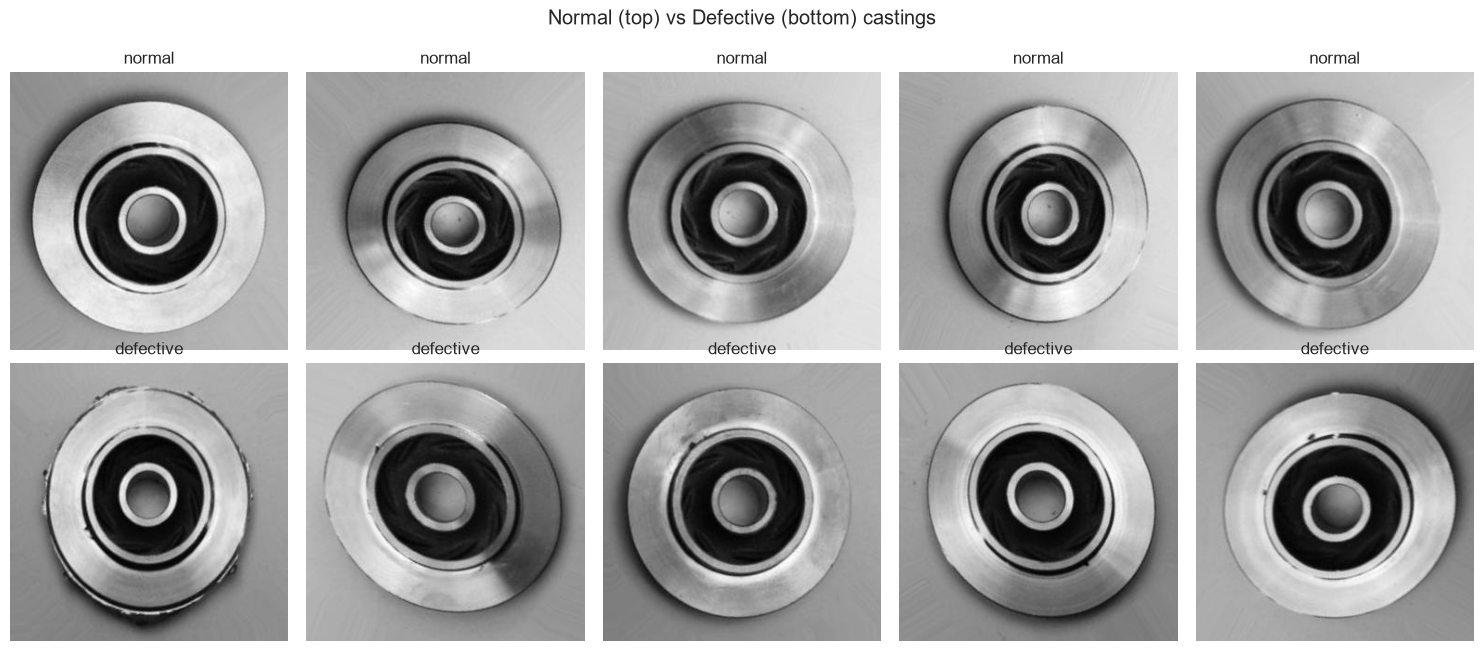

In [6]:
# Sample images from each class
rng = np.random.RandomState(SEED)
fig, axes = plt.subplots(2, 5, figsize=(15, 6.5))
for r, cls in enumerate(CLASS_NAMES):
    paths = meta[(meta.orig_split == "train") & (meta.label == cls)]["path"].values
    for c, p in enumerate(rng.choice(paths, 5, replace=False)):
        axes[r, c].imshow(Image.open(p).convert("RGB")); axes[r, c].axis("off")
        axes[r, c].set_title(cls)
plt.suptitle("Normal (top) vs Defective (bottom) castings", y=1.0); plt.tight_layout(); plt.show()

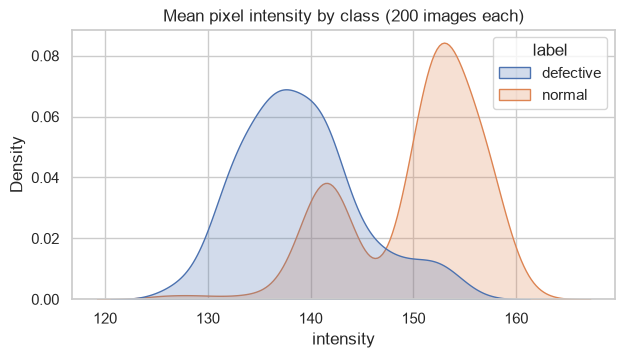

In [7]:
# Average pixel intensity per class (a quick check that the classes are not trivially separable by brightness)
def mean_intensity(p):
    return np.asarray(Image.open(p).convert("L"), dtype="float32").mean()

n_s = min(200, meta[meta.orig_split == "train"]["label"].value_counts().min())
sample = meta[meta.orig_split == "train"].groupby("label").sample(n_s, random_state=SEED, replace=False)
sample["intensity"] = sample["path"].map(mean_intensity)
plt.figure(figsize=(7, 3.5))
sns.kdeplot(data=sample, x="intensity", hue="label", fill=True, common_norm=False)
plt.title(f"Mean pixel intensity by class ({n_s} images each)"); plt.show()

## 4. Stratified train / validation split
`train/` is split **80 / 20** with `stratify=label`, preserving the class ratio. `test/` is copied as-is into the new structure and is **not touched again until Section 9**.

Expected: Train 2,300 normal + 3,006 defective = 5,306. Validation 575 normal + 752 defective = 1,327.

In [8]:
train_pool = meta[meta.orig_split == "train"]
train_part, val_part = train_test_split(train_pool, test_size=0.20, stratify=train_pool["label"], random_state=SEED)
test_part = meta[meta.orig_split == "test"]

splits = {"train": train_part, "val": val_part, "test": test_part}

if os.path.exists(SPLIT_DIR):
    shutil.rmtree(SPLIT_DIR)

for split, frame in splits.items():
    for cls in CLASS_NAMES:
        os.makedirs(os.path.join(SPLIT_DIR, split, cls), exist_ok=True)
    for p, cls in zip(frame["path"], frame["label"]):
        dest = os.path.join(SPLIT_DIR, split, cls, os.path.basename(p))
        i = 1
        while os.path.exists(dest):                      # avoid name collisions
            stem, ext = os.path.splitext(os.path.basename(p))
            dest = os.path.join(SPLIT_DIR, split, cls, f"{stem}_{i}{ext}"); i += 1
        shutil.copy2(p, dest)

summary = pd.DataFrame({s: f["label"].value_counts() for s, f in splits.items()}).reindex(CLASS_NAMES)
summary.loc["total"] = summary.sum()
print(summary)
print("\nFinal structure:")
for s in splits:
    for c in CLASS_NAMES:
        print(f"  {SPLIT_DIR}/{s}/{c}/  ({len(os.listdir(os.path.join(SPLIT_DIR, s, c)))} images)")

           train   val  test
label                       
normal      2300   575   262
defective   3006   752   453
total       5306  1327   715

Final structure:
  ../data/casting_split/train/normal/  (2300 images)
  ../data/casting_split/train/defective/  (3006 images)
  ../data/casting_split/val/normal/  (575 images)
  ../data/casting_split/val/defective/  (752 images)
  ../data/casting_split/test/normal/  (262 images)
  ../data/casting_split/test/defective/  (453 images)


## 5. Data pipelines and augmentation
- Images are loaded at each model's required size (128 for the custom CNN, 224 for the backbones).
- Labels: `normal = 0`, `defective = 1` (set explicitly through `class_names`).
- **Augmentation** (rotation, flip, zoom, brightness) is a Keras layer inside each model, so it is active only during training.
- **Normalisation** is also inside the model: `/255` for the custom CNN, backbone-specific preprocessing for VGG16 and MobileNetV2.

In [9]:
def make_ds(split, img_size, shuffle):
    ds = keras.utils.image_dataset_from_directory(
        os.path.join(SPLIT_DIR, split), labels="inferred", label_mode="binary",
        class_names=CLASS_NAMES, color_mode="rgb", batch_size=BATCH,
        image_size=(img_size, img_size), shuffle=shuffle, seed=SEED)
    return ds.prefetch(tf.data.AUTOTUNE)

train_cnn, val_cnn = make_ds("train", IMG_CNN, True), make_ds("val", IMG_CNN, False)
train_tl,  val_tl  = make_ds("train", IMG_TL,  True), make_ds("val", IMG_TL,  False)

# Class weights (balanced) to offset the normal/defective imbalance
n0, n1 = len(train_part[train_part.label == "normal"]), len(train_part[train_part.label == "defective"])
class_weight = {0: (n0 + n1) / (2 * n0), 1: (n0 + n1) / (2 * n1)}
print("class_weight:", {k: round(v, 3) for k, v in class_weight.items()})

Found 5306 files belonging to 2 classes.
Found 1327 files belonging to 2 classes.
Found 5306 files belonging to 2 classes.
Found 1327 files belonging to 2 classes.
class_weight: {0: 1.153, 1: 0.883}


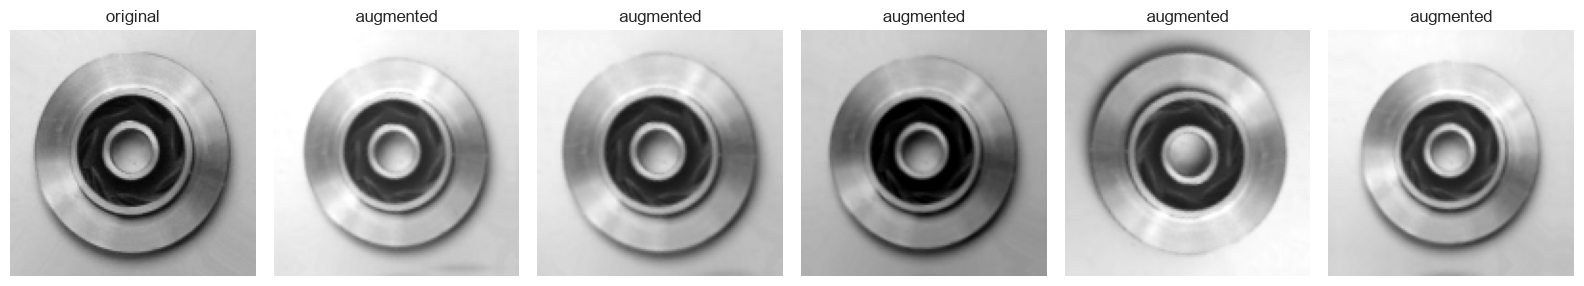

In [10]:
def make_augmentation():
    return keras.Sequential([
        layers.RandomFlip("horizontal_and_vertical"),
        layers.RandomRotation(0.05),                                  # about +/-18 degrees
        layers.RandomZoom(0.10),
        layers.RandomBrightness(0.20, value_range=(0, 255)),
    ], name="augmentation")

# Visualise what augmentation does to one training image
imgs, _ = next(iter(train_cnn))
aug = make_augmentation()
fig, axes = plt.subplots(1, 6, figsize=(16, 3))
axes[0].imshow(imgs[0].numpy().astype("uint8")); axes[0].set_title("original")
for a in axes[1:]:
    a.imshow(np.clip(aug(imgs[:1], training=True)[0].numpy(), 0, 255).astype("uint8")); a.set_title("augmented")
for a in axes: a.axis("off")
plt.tight_layout(); plt.show()

## Helpers

In [11]:
def make_callbacks(patience=5):
    return [callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True),
            callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-7)]

def plot_history(histories, title):
    # histories: list of Keras History objects (e.g. head stage + fine-tune stage) joined end to end
    acc  = sum([h.history["accuracy"]     for h in histories], [])
    vacc = sum([h.history["val_accuracy"] for h in histories], [])
    loss = sum([h.history["loss"]         for h in histories], [])
    vloss= sum([h.history["val_loss"]     for h in histories], [])
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    ax[0].plot(loss, label="train"); ax[0].plot(vloss, label="val"); ax[0].set_title(f"{title}: loss"); ax[0].legend()
    ax[1].plot(acc, label="train");  ax[1].plot(vacc, label="val");  ax[1].set_title(f"{title}: accuracy"); ax[1].legend()
    if len(histories) > 1:
        cut = len(histories[0].history["loss"]) - 0.5
        for a in ax: a.axvline(cut, color="gray", ls="--", lw=1)
    for a in ax: a.set_xlabel("epoch")
    plt.tight_layout(); plt.show()

def predict_ds(model, ds):
    y_true = np.concatenate([y.numpy().ravel() for _, y in ds]).astype(int)
    prob = model.predict(ds, verbose=0).ravel()
    return y_true, prob, (prob >= 0.5).astype(int)

def clf_metrics(y_true, prob, pred):
    # 'weighted' averages are the ones comparable with the brief (accuracy == weighted recall).
    # The 'defective' columns describe the positive class alone, which is what a plant manager cares about.
    pw, rw, fw, _ = precision_recall_fscore_support(y_true, pred, average="weighted", zero_division=0)
    pd_, rd, fd, _ = precision_recall_fscore_support(y_true, pred, average="binary", pos_label=1, zero_division=0)
    return {"Accuracy": accuracy_score(y_true, pred), "Precision (weighted)": pw, "Recall (weighted)": rw,
            "F1 (weighted)": fw, "Precision (defective)": pd_, "Recall (defective)": rd, "F1 (defective)": fd,
            "ROC-AUC": roc_auc_score(y_true, prob)}

## 6. Custom CNN (from scratch)
Four Conv-BatchNorm-ReLU-MaxPool blocks with growing filters, global average pooling, a dense layer with heavy dropout, and a sigmoid output.

In [12]:
def build_custom_cnn(img_size=IMG_CNN):
    inp = keras.Input((img_size, img_size, 3), name="image")
    x = make_augmentation()(inp)
    x = layers.Rescaling(1.0 / 255)(x)
    for f, d in zip((32, 64, 128, 256), (0.10, 0.15, 0.20, 0.25)):
        x = layers.Conv2D(f, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
        x = layers.MaxPooling2D(2)(x)
        x = layers.Dropout(d)(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.5)(x)
    out = layers.Dense(1, activation="sigmoid", name="defective_prob")(x)
    m = keras.Model(inp, out, name="custom_cnn")
    m.compile(optimizer=keras.optimizers.Adam(LR_CNN), loss="binary_crossentropy", metrics=["accuracy"])
    return m

cnn = build_custom_cnn()
cnn.summary()

Model: "custom_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 8, 8, 256)      │             

 Total params: 422,881 (1.61 MB)

 Trainable params: 421,921 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

Epoch 1/30
166/166 - 94s - 567ms/step - accuracy: 0.6828 - loss: 0.6049 - val_accuracy: 0.5667 - val_loss: 1.4248 - learning_rate: 0.0010
Epoch 2/30
166/166 - 82s - 494ms/step - accuracy: 0.7987 - loss: 0.4438 - val_accuracy: 0.5667 - val_loss: 3.8719 - learning_rate: 0.0010
Epoch 3/30
166/166 - 81s - 489ms/step - accuracy: 0.8456 - loss: 0.3520 - val_accuracy: 0.5667 - val_loss: 3.1269 - learning_rate: 0.0010
Epoch 4/30
166/166 - 80s - 484ms/step - accuracy: 0.8835 - loss: 0.2827 - val_accuracy: 0.5667 - val_loss: 6.3736 - learning_rate: 5.0000e-04
Epoch 5/30
166/166 - 80s - 484ms/step - accuracy: 0.9052 - loss: 0.2322 - val_accuracy: 0.5667 - val_loss: 11.3466 - learning_rate: 5.0000e-04
Epoch 6/30
166/166 - 80s - 481ms/step - accuracy: 0.9235 - loss: 0.1990 - val_accuracy: 0.5667 - val_loss: 5.8439 - learning_rate: 2.5000e-04
Epoch 7/30
166/166 - 81s - 485ms/step - accuracy: 0.9235 - loss: 0.1922 - val_accuracy: 0.5667 - val_loss: 3.5485 - learning_rate: 2.5000e-04
Epoch 8/30
166/16

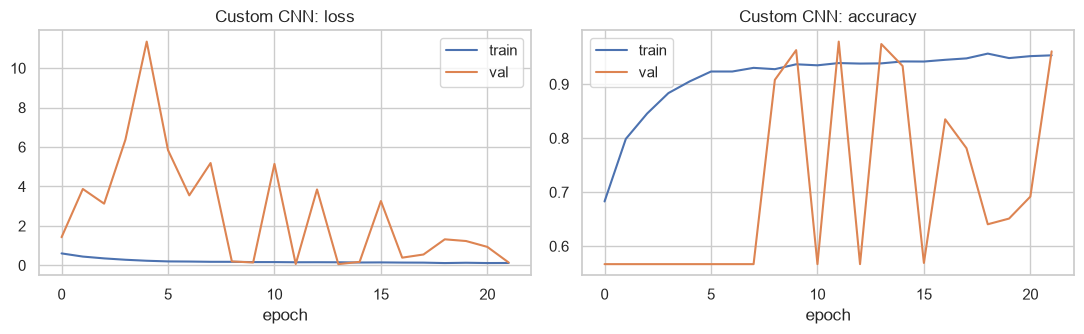

In [13]:
hist_cnn = cnn.fit(train_cnn, validation_data=val_cnn, epochs=EPOCHS_CNN, class_weight=class_weight,
                   callbacks=make_callbacks(patience=8), verbose=2)
plot_history([hist_cnn], "Custom CNN")

## 7. Transfer learning: VGG16 and MobileNetV2

In [14]:
BACKBONES = {
    "vgg16": dict(
        build=lambda: keras.applications.VGG16(include_top=False, weights=WEIGHTS, input_shape=(IMG_TL, IMG_TL, 3)),
        preprocess=lambda x: keras.applications.vgg16.preprocess_input(x),
        unfreeze_last=8),
    "mobilenetv2": dict(
        build=lambda: keras.applications.MobileNetV2(include_top=False, weights=WEIGHTS, input_shape=(IMG_TL, IMG_TL, 3)),
        preprocess=lambda x: layers.Rescaling(1.0 / 127.5, offset=-1.0)(x),
        unfreeze_last=30),
}

def build_transfer(name):
    cfg = BACKBONES[name]
    inp = keras.Input((IMG_TL, IMG_TL, 3), name="image")
    x = make_augmentation()(inp)
    x = cfg["preprocess"](x)
    base = cfg["build"](); base.trainable = False
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(1, activation="sigmoid", name="defective_prob")(x)
    m = keras.Model(inp, out, name=name)
    m.compile(optimizer=keras.optimizers.Adam(LR_HEAD), loss="binary_crossentropy", metrics=["accuracy"])
    return m, base

def unfreeze_top(model, base, n_layers):
    base.trainable = True
    for layer in base.layers[:-n_layers]:
        layer.trainable = False
    for layer in base.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False
    model.compile(optimizer=keras.optimizers.Adam(LR_FT), loss="binary_crossentropy", metrics=["accuracy"])
    print(f"{model.name}: {sum(l.trainable for l in base.layers)} / {len(base.layers)} backbone layers trainable")

def train_transfer(name):
    model, base = build_transfer(name)
    h1 = model.fit(train_tl, validation_data=val_tl, epochs=EPOCHS_HEAD, class_weight=class_weight,
                   callbacks=make_callbacks(patience=3), verbose=2)
    unfreeze_top(model, base, BACKBONES[name]["unfreeze_last"])
    h2 = model.fit(train_tl, validation_data=val_tl, epochs=EPOCHS_FT, class_weight=class_weight,
                   callbacks=make_callbacks(patience=4), verbose=2)
    return model, [h1, h2]

Epoch 1/8
166/166 - 553s - 3s/step - accuracy: 0.6504 - loss: 0.7231 - val_accuracy: 0.8320 - val_loss: 0.3650 - learning_rate: 0.0010
Epoch 2/8
166/166 - 545s - 3s/step - accuracy: 0.8762 - loss: 0.3098 - val_accuracy: 0.9179 - val_loss: 0.2271 - learning_rate: 0.0010
Epoch 3/8
166/166 - 526s - 3s/step - accuracy: 0.9233 - loss: 0.2164 - val_accuracy: 0.9337 - val_loss: 0.1791 - learning_rate: 0.0010
Epoch 4/8
166/166 - 526s - 3s/step - accuracy: 0.9518 - loss: 0.1650 - val_accuracy: 0.9405 - val_loss: 0.1443 - learning_rate: 0.0010
Epoch 5/8
166/166 - 528s - 3s/step - accuracy: 0.9582 - loss: 0.1398 - val_accuracy: 0.9608 - val_loss: 0.1214 - learning_rate: 0.0010
Epoch 6/8
166/166 - 545s - 3s/step - accuracy: 0.9689 - loss: 0.1208 - val_accuracy: 0.9653 - val_loss: 0.1084 - learning_rate: 0.0010
Epoch 7/8
166/166 - 540s - 3s/step - accuracy: 0.9738 - loss: 0.1033 - val_accuracy: 0.9563 - val_loss: 0.1090 - learning_rate: 0.0010
Epoch 8/8
166/166 - 533s - 3s/step - accuracy: 0.9776 -

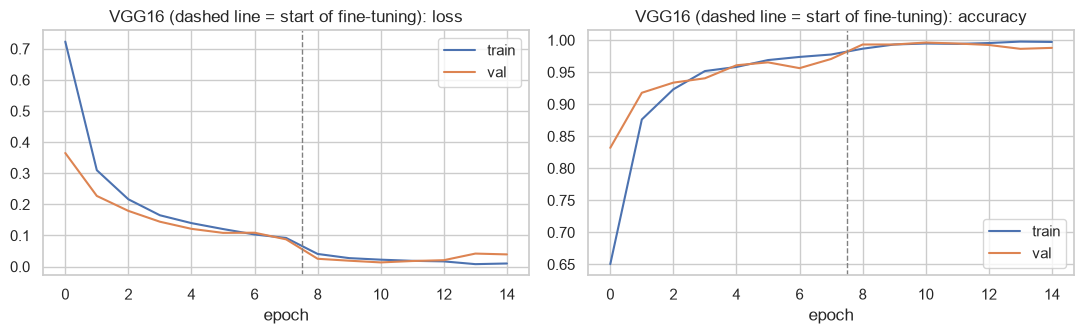

In [15]:
vgg, hist_vgg = train_transfer("vgg16")
plot_history(hist_vgg, "VGG16 (dashed line = start of fine-tuning)")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/8
166/166 - 93s - 560ms/step - accuracy: 0.8583 - loss: 0.3760 - val_accuracy: 0.9156 - val_loss: 0.2525 - learning_rate: 0.0010
Epoch 2/8
166/166 - 86s - 519ms/step - accuracy: 0.9433 - loss: 0.1966 - val_accuracy: 0.9382 - val_loss: 0.1917 - learning_rate: 0.0010
Epoch 3/8
166/166 - 88s - 528ms/step - accuracy: 0.9568 - loss: 0.1505 - val_accuracy: 0.9616 - val_loss: 0.1450 - learning_rate: 0.0010
Epoch 4/8
166/166 - 85s - 512ms/step - accuracy: 0.9700 - loss: 0.1203 - val_accuracy: 0.9714 - val_loss: 0.1214 - learning_rate: 0.0010
Epoch 5/8
166/166 - 85s - 512ms/step - accuracy: 0.9776 - loss: 0.0979 - val_accuracy: 0.9691 - val_loss: 0.1141 - learning_rate: 0.0010
Epoch 6/8
166/166 - 87s - 525ms/step - accuracy: 0.9768 - loss: 0.0907 - val_accuracy: 0.9766 - val_loss: 0.0954 - learning_rate: 0.0010
Epoch 7/8
166/166 - 85s - 515ms/step - accuracy: 0.9812 - loss: 0.0815 - val_accuracy: 0.9781 - val_loss: 0.0874 - learning_rate:

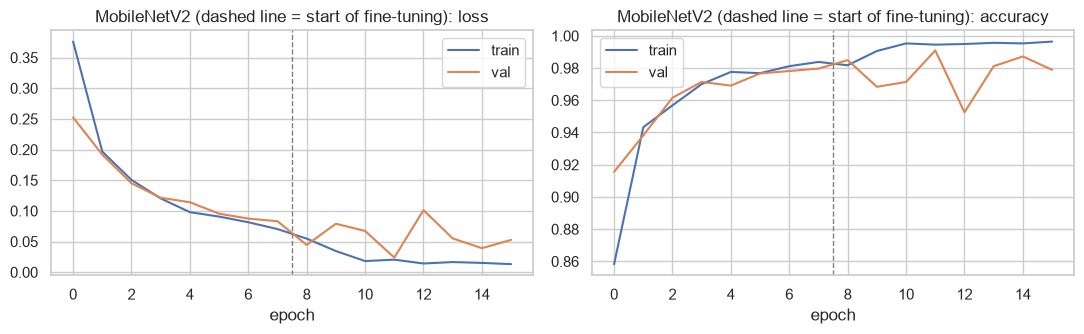

In [16]:
mobilenet, hist_mob = train_transfer("mobilenetv2")
plot_history(hist_mob, "MobileNetV2 (dashed line = start of fine-tuning)")

## 8. Validation comparison (used for model and checkpoint selection)
All decisions are made on the **validation** set. The held-out test set has not been touched yet.

In [17]:
models = {"Custom CNN": (cnn, val_cnn), "VGG16": (vgg, val_tl), "MobileNetV2": (mobilenet, val_tl)}

val_rows = {}
for name, (m, ds) in models.items():
    y, p, yhat = predict_ds(m, ds)
    val_rows[name] = clf_metrics(y, p, yhat)
val_results = pd.DataFrame(val_rows).T.round(4)
val_results

,Accuracy,Precision (weighted),Recall (weighted),F1 (weighted),Precision (defective),Recall (defective),F1 (defective),ROC-AUC
Custom CNN,0.9744,0.9744,0.9744,0.9744,0.9774,0.9774,0.9774,0.9983
VGG16,0.9962,0.9963,0.9962,0.9962,1.0000,0.9934,0.9967,0.9997
MobileNetV2,0.9910,0.9910,0.9910,0.9910,0.9920,0.9920,0.9920,0.9995


## 9. Final test evaluation (run once)

In [18]:
test_cnn, test_tl = make_ds("test", IMG_CNN, False), make_ds("test", IMG_TL, False)
test_sets = {"Custom CNN": test_cnn, "VGG16": test_tl, "MobileNetV2": test_tl}

test_out, test_rows = {}, {}
for name, (m, _) in models.items():
    y, p, yhat = predict_ds(m, test_sets[name])
    test_out[name] = (y, p, yhat)
    test_rows[name] = clf_metrics(y, p, yhat)

test_results = pd.DataFrame(test_rows).T.round(4)
display(test_results)

print("Brief's comparison view (weighted averages, as in the expected-metrics table):")
display((test_results[["Accuracy", "Precision (weighted)", "Recall (weighted)"]] * 100).round(2).astype(str) + " %")

Found 715 files belonging to 2 classes.
Found 715 files belonging to 2 classes.


,Accuracy,Precision (weighted),Recall (weighted),F1 (weighted),Precision (defective),Recall (defective),F1 (defective),ROC-AUC
Custom CNN,0.9734,0.9736,0.9734,0.9733,0.9697,0.9890,0.9792,0.9975
VGG16,0.9958,0.9958,0.9958,0.9958,0.9978,0.9956,0.9967,0.9997
MobileNetV2,0.9944,0.9944,0.9944,0.9944,0.9956,0.9956,0.9956,0.9994


Brief's comparison view (weighted averages, as in the expected-metrics table):


,Accuracy,Precision (weighted),Recall (weighted)
Custom CNN,97.34 %,97.36 %,97.34 %
VGG16,99.58 %,99.58 %,99.58 %
MobileNetV2,99.44 %,99.44 %,99.44 %


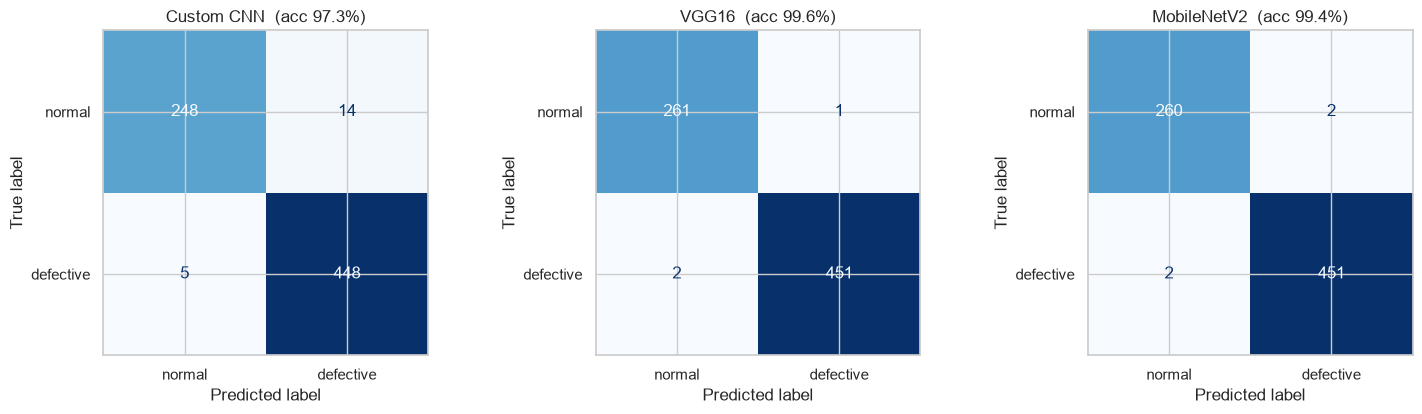

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
for ax, (name, (y, p, yhat)) in zip(axes, test_out.items()):
    ConfusionMatrixDisplay(confusion_matrix(y, yhat), display_labels=CLASS_NAMES).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{name}  (acc {accuracy_score(y, yhat):.1%})")
plt.tight_layout(); plt.show()

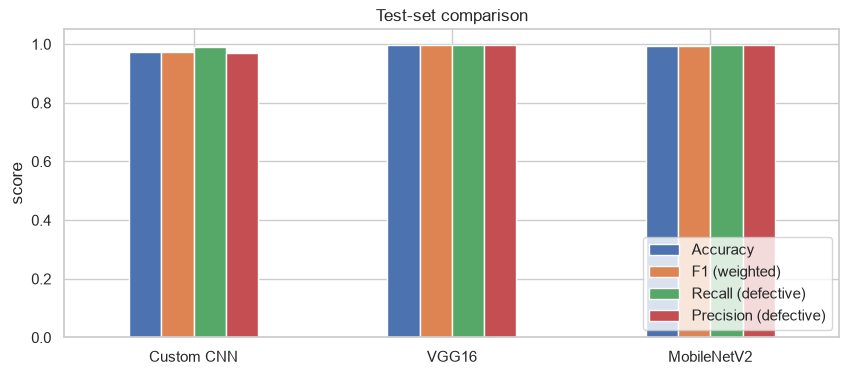

In [20]:
plot_df = test_results[["Accuracy", "F1 (weighted)", "Recall (defective)", "Precision (defective)"]]
plot_df.plot.bar(figsize=(10, 4), rot=0, ylim=(0, 1.05))
plt.title("Test-set comparison"); plt.ylabel("score"); plt.legend(loc="lower right"); plt.show()

## 10. Best model and error analysis

In [21]:
best_name = test_results["F1 (weighted)"].idxmax()
print("Best model by weighted F1:", best_name)
print(test_results.loc[best_name].to_string())

best_model = models[best_name][0]
y, p, yhat = test_out[best_name]
tn, fp, fn, tp = confusion_matrix(y, yhat).ravel()
print(f"\nTrue negatives {tn} | False positives (good part flagged) {fp} | False negatives (defect missed) {fn} | True positives {tp}")

Best model by weighted F1: VGG16
Accuracy                 0.9958
Precision (weighted)     0.9958
Recall (weighted)        0.9958
F1 (weighted)            0.9958
Precision (defective)    0.9978
Recall (defective)       0.9956
F1 (defective)           0.9967
ROC-AUC                  0.9997

True negatives 261 | False positives (good part flagged) 1 | False negatives (defect missed) 2 | True positives 451


3 misclassified of 715


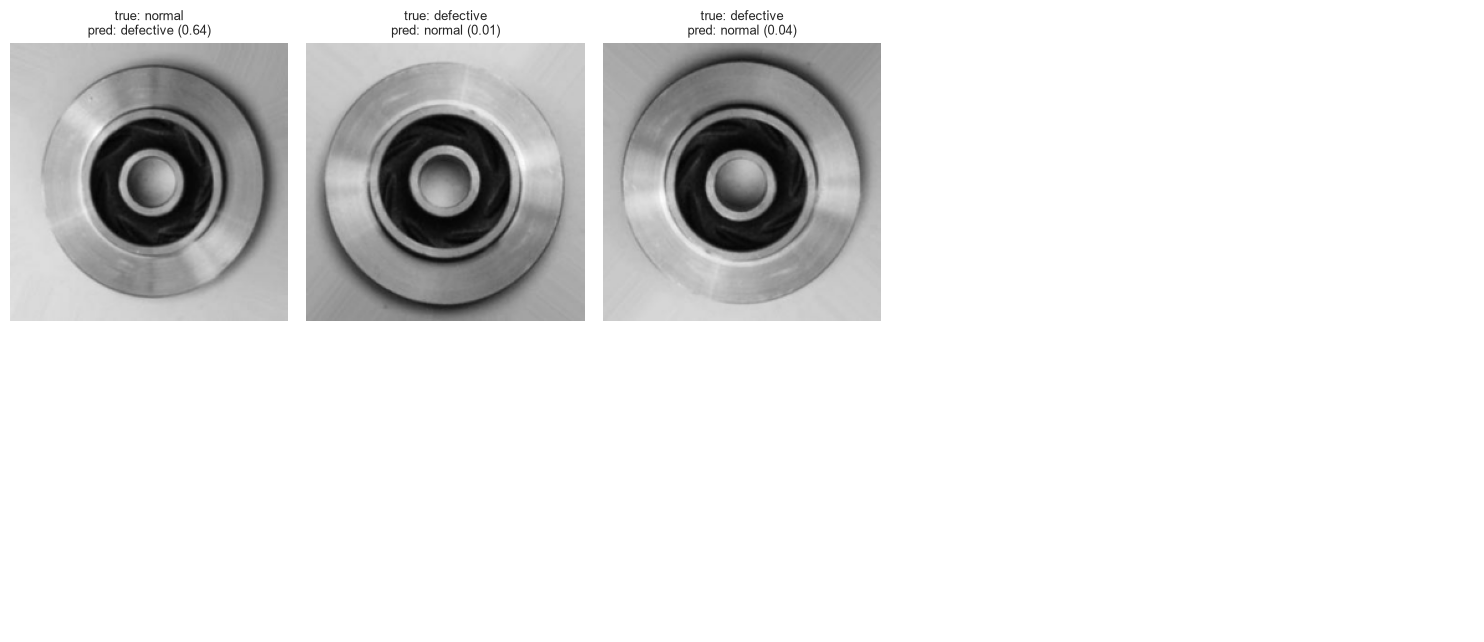

In [22]:
# Look at the images the best model got wrong
size = IMG_TL if best_name != "Custom CNN" else IMG_CNN
test_for_best = test_sets[best_name]
imgs_all = np.concatenate([x.numpy() for x, _ in test_for_best])
wrong = np.where(yhat != y)[0]
print(f"{len(wrong)} misclassified of {len(y)}")

show = wrong[:10]
if len(show):
    fig, axes = plt.subplots(2, 5, figsize=(15, 6.5))
    for a in axes.ravel(): a.axis("off")
    for a, i in zip(axes.ravel(), show):
        a.imshow(imgs_all[i].astype("uint8"))
        a.set_title(f"true: {CLASS_NAMES[y[i]]}\npred: {CLASS_NAMES[yhat[i]]} ({p[i]:.2f})", fontsize=9)
    plt.tight_layout(); plt.show()

## 12. Save models and artifacts
Each model is a self-contained `.keras` file (augmentation and preprocessing are inside). The Streamlit app needs only the model path, input size and class names.

In [23]:
cnn.save("../models/custom_cnn.keras")
vgg.save("../models/vgg16.keras")
mobilenet.save("../models/mobilenetv2.keras")

best_file = {"Custom CNN": "custom_cnn.keras", "VGG16": "vgg16.keras", "MobileNetV2": "mobilenetv2.keras"}[best_name]
best_size = IMG_CNN if best_name == "Custom CNN" else IMG_TL

with open("../artifacts/class_config.json", "w") as f:
    json.dump({"class_names": CLASS_NAMES, "positive_class": "defective", "threshold": 0.5,
               "best_model": best_file, "best_model_input_size": best_size,
               "input_sizes": {"custom_cnn.keras": IMG_CNN, "vgg16.keras": IMG_TL, "mobilenetv2.keras": IMG_TL},
               "note": "Feed raw RGB pixels in [0, 255]; rescaling/preprocessing is inside the model."}, f, indent=2)

test_results.to_csv("../artifacts/classification_results.csv")
val_results.to_csv("../artifacts/classification_val_results.csv")

# Sanity check: reload every model and confirm identical predictions
for fname, ds in [("custom_cnn.keras", test_cnn), ("vgg16.keras", test_tl), ("mobilenetv2.keras", test_tl)]:
    reloaded = keras.models.load_model(f"../models/{fname}")
    orig = {"custom_cnn.keras": cnn, "vgg16.keras": vgg, "mobilenetv2.keras": mobilenet}[fname]
    xb, _ = next(iter(ds))
    assert np.allclose(reloaded.predict(xb, verbose=0), orig.predict(xb, verbose=0), atol=1e-4), fname

print("Saved models:", sorted(os.listdir("../models")))
print("Saved artifacts:", sorted(os.listdir("../artifacts")))
print("Best model for the Streamlit app:", best_file)

Saved models: ['.gitkeep', 'ann.keras', 'custom_cnn.keras', 'lstm.keras', 'mobilenetv2.keras', 'rnn.keras', 'vgg16.keras']
Saved artifacts: ['.gitkeep', 'class_config.json', 'classification_results.csv', 'classification_val_results.csv', 'config.json', 'regression_results.csv', 'scaler.pkl']
Best model for the Streamlit app: vgg16.keras
